In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
data = pd.read_csv('/content/drive/MyDrive/digit_classification/train.csv')

In [4]:
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
data = np.array(data)
m, n = data.shape
np.random.shuffle(data)

In [6]:
print(m,n)

42000 785


In [7]:
train_data = data[0:int(0.8*m), :]
val_data = data[int(0.8*m):m, :]

X_train = train_data[:, 1:].T
X_train = X_train / 255.0
Y_train = train_data[:, 0]

X_val = val_data[:, 1:].T
X_val = X_val / 255.0
Y_val = val_data[:, 0]

In [8]:
print(X_train.shape, Y_train.shape)
print(X_val.shape, Y_val.shape)

(784, 33600) (33600,)
(784, 8400) (8400,)


In [10]:
def initialize_params():
  W1 = np.random.randn(10, 784) * np.sqrt(2.0 / 784)
  b1 = np.zeros((10, 1))
  W2 = np.random.randn(10, 10) * np.sqrt(2.0 / 10)
  b2 = np.zeros((10, 1))
  return W1, b1, W2, b2

def ReLu(Z):
  return np.maximum(Z, 0)

def ReLu_deriv(Z):
    return Z > 0

def softmax(Z):
  exps = np.exp(Z)
  return exps / np.sum(exps, axis=0)

def forward_prop(W1,b1,W2,b2,X):
  Z1 = W1.dot(X) + b1
  A1 = ReLu(Z1)
  Z2 = W2.dot(A1) + b2
  A2 = softmax(Z2)
  return Z1, A1, Z2, A2

def one_hot_converter(Y):
  one_hot_Y = np.zeros((Y.size, Y.max() + 1))
  one_hot_Y[np.arange(Y.size), Y] = 1
  one_hot_Y = one_hot_Y.T
  return one_hot_Y

def backward_prop(W1,b1,W2,b2,Z1,A1,Z2,A2,X,Y):
  one_hot_Y = one_hot_converter(Y)
  dZ2 = A2 - one_hot_Y
  dW2 = 1 / m * dZ2.dot(A1.T)
  db2 = 1 / m * np.sum(dZ2)
  dZ1 = W2.T.dot(dZ2) * (Z1 > 0)
  dW1 = 1 / m * dZ1.dot(X.T)
  db1 = 1 / m * np.sum(dZ1)
  return dW1, db1, dW2, db2

def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):
  W1 = W1 - learning_rate * dW1
  b1 = b1 - learning_rate * db1
  W2 = W2 - learning_rate * dW2
  b2 = b2 - learning_rate * db2
  return W1, b1, W2, b2

def get_predictions(A2):
  return np.argmax(A2, 0)

def get_accuracy(predictions, Y):
  print(predictions, Y)
  return np.sum(predictions == Y) / Y.size

def gradient_descent(X, Y, alpha, iterations):
  W1, b1, W2, b2 = initialize_params()
  for i in range(iterations):
    Z1, A1, Z2, A2 = forward_prop(W1,b1,W2,b2,X)
    dW1, db1, dW2, db2 = backward_prop(W1,b1,W2,b2,Z1,A1,Z2,A2,X,Y)
    W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)

    if i % 10 == 0:
      print("Iteration: ", i)
      print("Accuracy: ", get_accuracy(get_predictions(A2), Y))
  return W1, b1, W2, b2

In [11]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, 0.10, 1000)

Iteration:  0
[8 6 8 ... 6 6 6] [3 8 8 ... 1 0 8]
Accuracy:  0.12223214285714286
Iteration:  10
[8 8 8 ... 8 6 8] [3 8 8 ... 1 0 8]
Accuracy:  0.2881845238095238
Iteration:  20
[4 2 8 ... 2 6 8] [3 8 8 ... 1 0 8]
Accuracy:  0.41291666666666665
Iteration:  30
[4 2 8 ... 2 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.5528571428571428
Iteration:  40
[8 2 8 ... 2 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.6153571428571428
Iteration:  50
[7 2 8 ... 2 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.6963095238095238
Iteration:  60
[7 2 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.748125
Iteration:  70
[7 8 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.7723809523809524
Iteration:  80
[7 8 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.7878571428571428
Iteration:  90
[7 8 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.7998511904761905
Iteration:  100
[7 8 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.8094642857142857
Iteration:  110
[7 8 8 ... 1 0 8] [3 8 8 ... 1 0 8]
Accuracy:  0.8176785714285715
Iteration:  120
[7 8 8 ... 1 0 8] [

Predicted label:  [1]
Actual label:  1


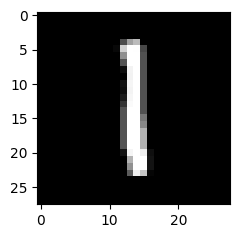

In [16]:
val_index = 1
Z1val, A1val, Z2val, A2val = forward_prop(W1,b1,W2,b2,X_val[:,val_index,None])
print("Predicted label: ",get_predictions(A2val))
print("Actual label: ",Y_val[val_index])

image_data = X_val[:,val_index,None]
image_data = image_data.reshape((28,28))
plt.figure(figsize=(2.5, 2.5))
plt.imshow(image_data, cmap='gray')
plt.show()



In [15]:
Z1val, A1val, Z2val, A2_val = forward_prop(W1, b1, W2, b2, X_val)
val_preds = get_predictions(A2_val)
print("Validation Accuracy:", get_accuracy(val_preds, Y_val))

[7 1 9 ... 7 1 2] [7 1 9 ... 7 1 2]
Validation Accuracy: 0.8997619047619048
